In [1]:
import pandas, numpy, sklearn, statsmodels, matplotlib
print("working")
print(pandas.__version__, sklearn.__version__, statsmodels.__version__)

working
2.3.2 1.7.1 0.14.4


In [1]:
import pandas as pd

df = pd.read_csv("accepted_2007_to_2018Q4.csv", nrows=200000, low_memory=False)
print(df.shape)
print(df["loan_status"].value_counts())
print(df["issue_d"].min(), df["issue_d"].max())
print([c for c in ["recoveries","total_rec_prncp","funded_amnt","last_pymnt_d"] if c in df.columns])

(200000, 151)
loan_status
Fully Paid            140992
Charged Off            35090
Current                22637
Late (31-120 days)       785
In Grace Period          347
Late (16-30 days)        148
Default                    1
Name: count, dtype: int64
Aug-2015 Sep-2015
['recoveries', 'total_rec_prncp', 'funded_amnt', 'last_pymnt_d']


In [8]:
import pandas as pd

wanted = ["loan_amnt","funded_amnt","term","int_rate","installment","grade","sub_grade",
          "emp_length","home_ownership","annual_inc","verification_status","issue_d",
          "loan_status","purpose","addr_state","dti","delinq_2yrs","fico_range_low",
          "fico_range_high","inq_last_6mths","open_acc","pub_rec","revol_bal","revol_util",
          "total_acc","total_rec_prncp","recoveries","last_pymnt_d"]

df = pd.read_csv("accepted_2007_to_2018Q4.csv",
                 usecols=lambda c: c in wanted, low_memory=False)
print(df.shape)

df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
print(df["issue_d"].min(), df["issue_d"].max())

resolved = df[df["loan_status"].isin(["Fully Paid","Charged Off","Default"])].copy()
resolved["default"] = resolved["loan_status"].isin(["Charged Off","Default"]).astype(int)

print(len(resolved), resolved["default"].mean())
print(resolved.groupby(resolved["issue_d"].dt.year)["default"].agg(["count","mean"]))

(2260701, 28)
2007-06-01 00:00:00 2018-12-01 00:00:00
1345350 0.19964990522912254
          count      mean
issue_d                  
2007        251  0.179283
2008       1562  0.158131
2009       4716  0.125954
2010      11536  0.128901
2011      21721  0.151789
2012      53367  0.161973
2013     134804  0.155960
2014     223103  0.184498
2015     375546  0.201850
2016     293105  0.232859
2017     169321  0.231330
2018      56318  0.157570


In [9]:
resolved["year"] = resolved["issue_d"].dt.year
resolved["term_m"] = resolved["term"].str.extract(r"(\d+)").astype(int)

# share of each year's loans that have a final outcome
all_by_year = df.groupby(df["issue_d"].dt.year).size()
res_by_year = resolved.groupby("year").size()
print((res_by_year / all_by_year).round(3))

# loan count and default rate by year and term
print(resolved.pivot_table(index="year", columns="term_m",
                           values="default", aggfunc=["count","mean"]).round(3))

# default rate by grade
print(resolved.groupby("grade")["default"].agg(["count","mean"]).round(3))

year
2007    0.416
2008    0.653
2009    0.893
2010    0.920
2011    1.000
2012    1.000
2013    1.000
2014    0.947
2015    0.892
2016    0.675
2017    0.382
2018    0.114
dtype: float64
           count            mean       
term_m        36       60     36     60
year                                   
2007       251.0      NaN  0.179    NaN
2008      1562.0      NaN  0.158    NaN
2009      4716.0      NaN  0.126    NaN
2010      8466.0   3070.0  0.099  0.210
2011     14101.0   7620.0  0.106  0.236
2012     43470.0   9897.0  0.136  0.277
2013    100422.0  34382.0  0.123  0.251
2014    162570.0  60533.0  0.137  0.311
2015    283026.0  92520.0  0.149  0.364
2016    232361.0  60744.0  0.198  0.364
2017    128551.0  40770.0  0.200  0.330
2018     41272.0  15046.0  0.132  0.226
        count   mean
grade               
A      235095  0.060
B      392748  0.134
C      381694  0.224
D      200966  0.304
E       93656  0.385
F       32059  0.452
G        9132  0.499


In [11]:
print(df["term"].isna().sum())   # expect 33
df = df.dropna(subset=["term", "loan_status"]).copy()

df["term_m"] = df["term"].str.extract(r"(\d+)")[0].astype(int)
df["year"] = df["issue_d"].dt.year

final_status = ["Fully Paid", "Charged Off", "Default",
                "Does not meet the credit policy. Status:Fully Paid",
                "Does not meet the credit policy. Status:Charged Off"]
df["has_outcome"] = df["loan_status"].isin(final_status)

print(df.pivot_table(index="year", columns="term_m",
                     values="has_outcome", aggfunc="mean").round(3))

resolved = df[df["has_outcome"]].copy()
resolved["default"] = resolved["loan_status"].str.contains("Charged Off|Default").astype(int)
print(len(resolved), resolved["default"].mean())

s36 = resolved[resolved["term_m"] == 36]
print(pd.crosstab(s36["year"], s36["grade"], normalize="index").round(3))

33
term_m     36     60
year                
2007    1.000    NaN
2008    1.000    NaN
2009    1.000    NaN
2010    1.000  1.000
2011    1.000  1.000
2012    1.000  1.000
2013    1.000  1.000
2014    1.000  0.829
2015    0.999  0.671
2016    0.718  0.548
2017    0.401  0.331
2018    0.120  0.100
1348099 0.19980728418313493
grade      A      B      C      D      E      F      G
year                                                  
2007   0.129  0.163  0.234  0.164  0.166  0.086  0.058
2008   0.133  0.248  0.242  0.175  0.119  0.046  0.036
2009   0.228  0.274  0.255  0.155  0.058  0.020  0.010
2010   0.280  0.306  0.226  0.137  0.037  0.010  0.004
2011   0.396  0.335  0.156  0.089  0.019  0.004  0.001
2012   0.247  0.387  0.228  0.117  0.018  0.002  0.001
2013   0.170  0.401  0.246  0.144  0.032  0.006  0.000
2014   0.217  0.329  0.271  0.126  0.043  0.012  0.001
2015   0.248  0.324  0.274  0.116  0.033  0.005  0.001
2016   0.204  0.346  0.287  0.119  0.034  0.008  0.002
2017   0.205  0

In [12]:
sample = resolved[(resolved["term_m"] == 36) & (resolved["year"].between(2012, 2015))].copy()
train = sample[sample["year"] <= 2014]
test = sample[sample["year"] == 2015]
print(len(train), len(test), round(train["default"].mean(), 4), round(test["default"].mean(), 4))

# default rate by grade and year: did the same grade get riskier?
print(sample.pivot_table(index="grade", columns="year", values="default", aggfunc="mean").round(3))

leak_cols = ["recoveries", "total_rec_prncp", "last_pymnt_d", "loan_status", "has_outcome"]
drop_cols = leak_cols + ["default", "issue_d", "year", "term", "term_m"]
pd_features = [c for c in sample.columns if c not in drop_cols]
print(pd_features)
print(train[pd_features].isna().mean().sort_values(ascending=False).head(8).round(3))

306462 283026 0.1325 0.1489
year    2012   2013   2014   2015
grade                            
A      0.072  0.046  0.054  0.054
B      0.126  0.098  0.107  0.119
C      0.176  0.153  0.172  0.194
D      0.211  0.204  0.222  0.262
E      0.219  0.233  0.270  0.328
F      0.184  0.268  0.295  0.424
G      0.167  0.267  0.363  0.461
['loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc']
emp_length        0.053
revol_util        0.001
loan_amnt         0.000
dti               0.000
revol_bal         0.000
pub_rec           0.000
open_acc          0.000
inq_last_6mths    0.000
dtype: float64


In [13]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score

def prep(d):
    d = d.copy()
    for c in ["int_rate", "revol_util"]:
        d[c] = pd.to_numeric(d[c].astype(str).str.rstrip("%"), errors="coerce")
    d["fico"] = (d["fico_range_low"] + d["fico_range_high"]) / 2
    d["emp_missing"] = d["emp_length"].isna().astype(int)
    d["emp_years"] = d["emp_length"].str.extract(r"(\d+)")[0].astype(float)
    d.loc[d["emp_length"] == "< 1 year", "emp_years"] = 0
    d["log_income"] = np.log1p(d["annual_inc"])
    return d

num_base = ["loan_amnt","dti","log_income","fico","emp_years","emp_missing","delinq_2yrs",
            "inq_last_6mths","open_acc","pub_rec","revol_bal","revol_util","total_acc"]
cat_base = ["home_ownership","verification_status","purpose"]

def make_model(num, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000))])

tr, te = prep(train), prep(test)
specs = {"borrower_only": (num_base, cat_base),
         "with_LC_pricing": (num_base + ["int_rate"], cat_base + ["grade"])}

for name, (num, cat) in specs.items():
    cols = num + cat
    m = make_model(num, cat).fit(tr[cols], tr["default"])
    p_tr = m.predict_proba(tr[cols])[:, 1]
    p_te = m.predict_proba(te[cols])[:, 1]
    auc_tr = roc_auc_score(tr["default"], p_tr)
    auc_te = roc_auc_score(te["default"], p_te)
    print(name, "| AUC train", round(auc_tr, 3), "test", round(auc_te, 3),
          "| Gini test", round(2 * auc_te - 1, 3))
    print("   mean predicted PD on test:", round(p_te.mean(), 4),
          "| actual:", round(te["default"].mean(), 4))

borrower_only | AUC train 0.655 test 0.658 | Gini test 0.317
   mean predicted PD on test: 0.1343 | actual: 0.1489
with_LC_pricing | AUC train 0.671 test 0.688 | Gini test 0.377
   mean predicted PD on test: 0.1257 | actual: 0.1489


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve

num, cat = specs["borrower_only"]
cols = num + cat

# 1. refit the borrower-only logistic model and score the test set
lr_b = make_model(num, cat).fit(tr[cols], tr["default"])
p_lr = lr_b.predict_proba(te[cols])[:, 1]

# 2. calibration by decile of predicted risk
cal = pd.DataFrame({"default": te["default"].values, "pred": p_lr})
cal["decile"] = pd.qcut(cal["pred"], 10, labels=False) + 1
print(cal.groupby("decile").agg(n=("default", "size"),
                                avg_pred=("pred", "mean"),
                                actual=("default", "mean")).round(3))

# 3. KS statistic
fpr, tpr, _ = roc_curve(te["default"], p_lr)
print("KS:", round((tpr - fpr).max(), 3))

# 4. Random Forest benchmark on the same features
rf = Pipeline([
    ("pre", ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                               ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
    ("rf", RandomForestClassifier(n_estimators=150, min_samples_leaf=100,
                                  n_jobs=-1, random_state=42))])
rf.fit(tr[cols], tr["default"])
p_rf = rf.predict_proba(te[cols])[:, 1]
print("RF test AUC:", round(roc_auc_score(te["default"], p_rf), 3),
      "| mean predicted PD:", round(p_rf.mean(), 4))

            n  avg_pred  actual
decile                         
1       28303     0.041   0.042
2       28303     0.068   0.073
3       28302     0.087   0.098
4       28303     0.102   0.111
5       28302     0.118   0.132
6       28303     0.134   0.151
7       28302     0.151   0.172
8       28303     0.173   0.198
9       28302     0.202   0.224
10      28303     0.268   0.287
KS: 0.229
RF test AUC: 0.661 | mean predicted PD: 0.1339


In [15]:
from sklearn.linear_model import LogisticRegression

# Part 1: recalibrate on Jan-Jun 2015, check on Jul-Dec 2015
te_a = te[te["issue_d"].dt.month <= 6]
te_b = te[te["issue_d"].dt.month > 6]
p_a = lr_b.predict_proba(te_a[cols])[:, 1]
p_b = lr_b.predict_proba(te_b[cols])[:, 1]

def logit(p):
    return np.log(p / (1 - p))

recal = LogisticRegression().fit(logit(p_a).reshape(-1, 1), te_a["default"])
p_b_new = recal.predict_proba(logit(p_b).reshape(-1, 1))[:, 1]

print("Jul-Dec 2015 actual default rate:", round(te_b["default"].mean(), 4))
print("predicted before:", round(p_b.mean(), 4), "| after:", round(p_b_new.mean(), 4))
print("AUC before:", round(roc_auc_score(te_b["default"], p_b), 4),
      "| after:", round(roc_auc_score(te_b["default"], p_b_new), 4))

# Part 2: LGD from defaulted loans in the training years
d = train[train["default"] == 1].copy()
d["ead"] = d["funded_amnt"] - d["total_rec_prncp"]
d = d[d["ead"] > 0]
d["lgd"] = (1 - d["recoveries"] / d["ead"]).clip(0, 1)
lgd_w = 1 - d["recoveries"].sum() / d["ead"].sum()
ead_factor = d["ead"].sum() / d["funded_amnt"].sum()
print("defaulted loans:", len(d), "| average LGD:", round(d["lgd"].mean(), 3),
      "| dollar-weighted LGD:", round(lgd_w, 3), "| EAD factor:", round(ead_factor, 3))

# Expected loss vs actual loss on Jul-Dec 2015
b = te_b.copy()
b["pd_new"] = p_b_new
ead_act = (b["funded_amnt"] - b["total_rec_prncp"]).clip(lower=0)
loss_act = np.where(b["default"] == 1, (ead_act - b["recoveries"]).clip(lower=0), 0)
pred_rate = (b["pd_new"] * lgd_w * ead_factor * b["loan_amnt"]).sum() / b["loan_amnt"].sum()
act_rate = loss_act.sum() / b["loan_amnt"].sum()
print("expected loss rate:", round(pred_rate, 4), "| actual loss rate:", round(act_rate, 4))

Jul-Dec 2015 actual default rate: 0.1471
predicted before: 0.1326 | after: 0.1468
AUC before: 0.6607 | after: 0.6607
defaulted loans: 40596 | average LGD: 0.87 | dollar-weighted LGD: 0.871 | EAD factor: 0.574
expected loss rate: 0.07 | actual loss rate: 0.0731


In [16]:
def stress(d, income_cut, fico_drop, lgd_add):
    s = d.copy()
    s["annual_inc"] = s["annual_inc"] * (1 - income_cut)
    s["log_income"] = np.log1p(s["annual_inc"])
    s["dti"] = s["dti"] / (1 - income_cut)
    s["fico"] = (s["fico"] - fico_drop).clip(lower=300)
    p = lr_b.predict_proba(s[cols])[:, 1]
    p = recal.predict_proba(logit(p).reshape(-1, 1))[:, 1]
    lgd = min(lgd_w + lgd_add, 1.0)
    loss = (p * lgd * ead_factor * s["loan_amnt"]).sum() / s["loan_amnt"].sum()
    return p.mean(), lgd, loss

scenarios = {"Baseline": (0, 0, 0), "Moderate": (0.10, 20, 0.05), "Severe": (0.20, 40, 0.10)}
rows = []
for name, (inc, fic, lg) in scenarios.items():
    pd_mean, lgd, loss = stress(te_b, inc, fic, lg)
    rows.append({"scenario": name, "avg_PD": round(pd_mean, 4),
                 "LGD": round(lgd, 3), "expected_loss": round(loss, 4)})

stress_df = pd.DataFrame(rows)
stress_df["loss_vs_baseline"] = (stress_df["expected_loss"] / stress_df.loc[0, "expected_loss"]).round(2)
print(stress_df)

   scenario  avg_PD    LGD  expected_loss  loss_vs_baseline
0  Baseline  0.1468  0.871         0.0700              1.00
1  Moderate  0.1890  0.921         0.0955              1.36
2    Severe  0.2419  0.971         0.1293              1.85


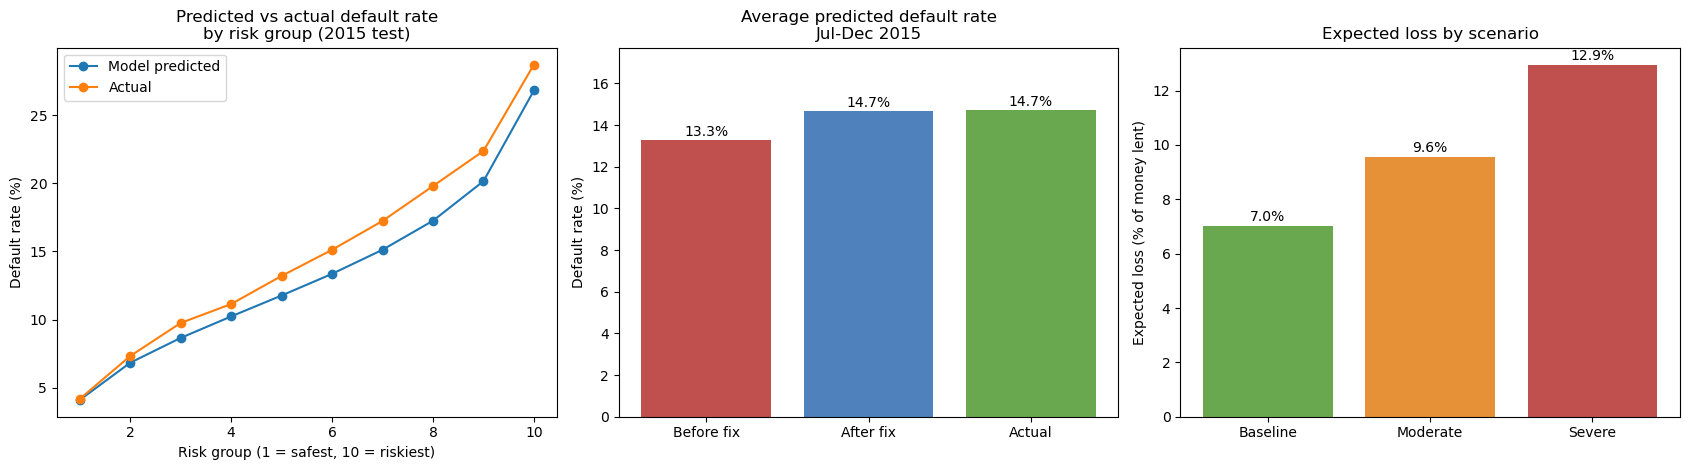

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1. Predicted vs actual default rate by risk group
c = cal.groupby("decile").agg(pred=("pred", "mean"), actual=("default", "mean"))
ax = axes[0]
ax.plot(c.index, c["pred"] * 100, marker="o", label="Model predicted")
ax.plot(c.index, c["actual"] * 100, marker="o", label="Actual")
ax.set_title("Predicted vs actual default rate\nby risk group (2015 test)")
ax.set_xlabel("Risk group (1 = safest, 10 = riskiest)")
ax.set_ylabel("Default rate (%)")
ax.legend()

# 2. Before and after the recalibration
ax = axes[1]
vals = [p_b.mean() * 100, p_b_new.mean() * 100, te_b["default"].mean() * 100]
ax.bar(["Before fix", "After fix", "Actual"], vals, color=["#c0504d", "#4f81bd", "#6aa84f"])
for i, v in enumerate(vals):
    ax.text(i, v + 0.2, f"{v:.1f}%", ha="center")
ax.set_ylim(0, max(vals) + 3)
ax.set_title("Average predicted default rate\nJul-Dec 2015")
ax.set_ylabel("Default rate (%)")

# 3. Stress test
ax = axes[2]
loss = stress_df["expected_loss"] * 100
ax.bar(stress_df["scenario"], loss, color=["#6aa84f", "#e69138", "#c0504d"])
for i, v in enumerate(loss):
    ax.text(i, v + 0.2, f"{v:.1f}%", ha="center")
ax.set_title("Expected loss by scenario")
ax.set_ylabel("Expected loss (% of money lent)")

plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()

In [19]:
cal_out = cal.groupby("decile").agg(avg_pred=("pred", "mean"),
                                    actual=("default", "mean"),
                                    n=("default", "size")).reset_index()
cal_out.to_csv("pbi_calibration.csv", index=False)

pd.DataFrame({"stage": ["Before fix", "After fix", "Actual"],
              "default_rate": [p_b.mean(), p_b_new.mean(), te_b["default"].mean()]}
             ).to_csv("pbi_recalibration.csv", index=False)

stress_df.to_csv("pbi_stress.csv", index=False)

sample.groupby(["year", "grade"])["default"].agg(loans="size", default_rate="mean"
             ).reset_index().to_csv("pbi_grade_year.csv", index=False)

In [20]:
import os
for f in ["pbi_calibration.csv", "pbi_recalibration.csv", "pbi_stress.csv", "pbi_grade_year.csv"]:
    print(f, os.path.exists(f))
print(pd.read_csv("pbi_grade_year.csv").shape)

pbi_calibration.csv True
pbi_recalibration.csv True
pbi_stress.csv True
pbi_grade_year.csv True
(28, 4)


In [21]:
import pandas as pd
from openpyxl import load_workbook
from openpyxl.worksheet.table import Table, TableStyleInfo

files = {"calibration": "pbi_calibration.csv",
         "recalibration": "pbi_recalibration.csv",
         "stress": "pbi_stress.csv",
         "grade_year": "pbi_grade_year.csv"}

with pd.ExcelWriter("pbi_results.xlsx", engine="openpyxl") as w:
    for sheet, f in files.items():
        pd.read_csv(f).to_excel(w, sheet_name=sheet, index=False)

wb = load_workbook("pbi_results.xlsx")
for ws in wb.worksheets:
    ref = f"A1:{ws.cell(row=ws.max_row, column=ws.max_column).coordinate}"
    t = Table(displayName=f"tbl_{ws.title}", ref=ref)
    t.tableStyleInfo = TableStyleInfo(name="TableStyleMedium2", showRowStripes=True)
    ws.add_table(t)
wb.save("pbi_results.xlsx")
print("saved")

saved


In [22]:
import os
os.system("open .")
print(os.getcwd())

/Users/rumeysacamur/Documents/credit-risk-pd


In [23]:
import shutil
shutil.copy("pbi_results.xlsx", os.path.expanduser("~/Desktop/pbi_results.xlsx"))
shutil.copy("pbi_calibration.csv", os.path.expanduser("~/Desktop/pbi_calibration.csv"))
print("copied")

copied
